# Counting Challenge — Non-AI solution (classical computer vision)

**Author:** Ramesh K

Counts the items (screws, bolts, nuts, washers) in every image and overlays a coloured mask on each counted item, using only OpenCV / NumPy / SciPy — no learned models.

## Method
1. **Resize** each photo so the long side is at most 2400 px.
2. **Background flattening** – a 3rd-order polynomial surface is fitted to the background pixels and divided out. This removes uneven lighting, coloured paper and lens vignetting.
3. **Otsu threshold + morphological opening** gives a clean foreground mask; holes are filled so a nut/washer becomes one solid blob.
4. **Unit area** – the typical area of a single item is estimated per image (robust iterated median of blob areas). No size is hard-coded, so the same code works for 1080p and 12 MP photos and for different object types.
5. **Mode detection** – if most single-sized blobs contain one round hole, the image is a nut/washer image (*ring mode*).
6. **Splitting touching items**
   * *Ring mode*: every round, correctly-sized hole is one nut/washer. Each nut's mask is the part of the blob nearest to its own hole (Voronoi split via a distance transform, limited to one nut radius), so even a pile of hundreds of touching nuts is split exactly.
   * *Solid mode* (screws/bolts): number of items in a blob = `round(blob_area / unit_area)`; the blob is then split into that many masks with k-means seeds + watershed on the distance transform.
7. Blobs touching the image border are vignetting / table edges, not items, and are ignored.
8. Output: count per image, coloured-mask overlay per image, `counts.csv`, and accuracy against `../ground_truth.csv`.


In [1]:
import os
import glob
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 1.24.3


## Configuration
`DATA_DIR` is found automatically (local repo layout, Kaggle or Colab). Change it if your images are somewhere else.

In [2]:
CANDIDATES = [
    os.environ.get("DATA_DIR", "-"),
    "../../data/CountingChallenge",
    "../data/CountingChallenge",
    "data/CountingChallenge",
    "/kaggle/input/countingchallenge/CountingChallenge",
    "/kaggle/input/countingchallenge",
    "/content/CountingChallenge",
]
DATA_DIR = next((p for p in CANDIDATES if glob.glob(os.path.join(p, "**", "*.jpg"), recursive=True)), None)
assert DATA_DIR, "Dataset not found - set DATA_DIR to the folder that contains the images"

OUT_DIR = "outputs"
GT_CSV = "../ground_truth.csv"
LONG_SIDE = 2400
SEED = 0

os.makedirs(OUT_DIR, exist_ok=True)
IMAGES = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True))
print(DATA_DIR, "->", len(IMAGES), "images")

../../data/CountingChallenge -> 25 images


## Pre-processing

In [3]:
def load_image(path, long_side=LONG_SIDE):
    im = cv2.imread(path)
    s = min(1.0, long_side / max(im.shape[:2]))
    return cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)


def _poly_terms(x, y):
    return [np.ones_like(x), x, y, x * x, x * y, y * y, x ** 3, y ** 3, x * x * y, x * y * y]


def darkness_map(bgr):
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    small = cv2.resize(g, None, fx=0.1, fy=0.1, interpolation=cv2.INTER_AREA)
    _, bg_mask = cv2.threshold(small.astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bg_mask = cv2.erode(bg_mask, np.ones((5, 5), np.uint8)) > 0
    h, w = small.shape
    yy, xx = np.mgrid[0:h, 0:w]
    A = np.stack(_poly_terms(xx[bg_mask] / w, yy[bg_mask] / h), 1)
    coef, *_ = np.linalg.lstsq(A, small[bg_mask], rcond=None)
    H, W = g.shape
    YY, XX = np.mgrid[0:H, 0:W]
    background = sum(c * t for c, t in zip(coef, _poly_terms(XX / W, YY / H)))
    return np.clip(1 - g / background, 0, 1)


def binarize(bgr):
    d8 = (darkness_map(bgr) * 255).astype(np.uint8)
    _, b = cv2.threshold(d8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return cv2.morphologyEx(b, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

## Single-item size, hole detection and blob splitting

In [4]:
def unit_area(areas):
    med = np.median(areas)
    for _ in range(3):
        sel = areas[(areas > 0.6 * med) & (areas < 1.5 * med)]
        if len(sel) == 0:
            break
        med = np.median(sel)
    return med


def find_round_holes(binary):
    cnts, hier = cv2.findContours(binary, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    holes = []
    if hier is None:
        return holes
    for c, h in zip(cnts, hier[0]):
        if h[3] < 0:
            continue
        a = cv2.contourArea(c)
        if a < 15:
            continue
        per = cv2.arcLength(c, True)
        circularity = 4 * np.pi * a / (per * per + 1e-6)
        if circularity <= 0.7:
            continue
        m = cv2.moments(c)
        holes.append((a, (m["m10"] / m["m00"], m["m01"] / m["m00"])))
    return holes


def split_blob(mask, n, seeds=None):
    if n <= 1:
        return [mask]
    if seeds is None:
        ys, xs = np.nonzero(mask)
        pts = np.stack([xs, ys], 1).astype(np.float32)
        crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.5)
        cv2.setRNGSeed(SEED)
        _, _, seeds = cv2.kmeans(pts, n, None, crit, 3, cv2.KMEANS_PP_CENTERS)
    markers = np.zeros(mask.shape, np.int32)
    for k, (x, y) in enumerate(seeds):
        cv2.circle(markers, (int(round(x)), int(round(y))), 2, k + 1, -1)
    markers[mask == 0] = len(seeds) + 1
    dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
    relief = cv2.normalize(-dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    ws = cv2.watershed(cv2.cvtColor(relief, cv2.COLOR_GRAY2BGR), markers)
    return [((ws == k + 1) & (mask > 0)).astype(np.uint8) for k in range(len(seeds))]


def nearest_seed_map(shape, seeds):
    no_seed = np.ones(shape, bool)
    seed_id = np.zeros(shape, np.int32)
    for k, (x, y) in enumerate(seeds):
        yy, xx = int(round(y)), int(round(x))
        no_seed[yy, xx] = False
        seed_id[yy, xx] = k
    dist, (iy, ix) = ndi.distance_transform_edt(no_seed, return_indices=True)
    return seed_id[iy, ix], dist

## Counting pipeline

In [5]:
def count_items(bgr):
    binary = binarize(bgr)
    H, W = binary.shape
    filled = ndi.binary_fill_holes(binary > 0).astype(np.uint8) * 255
    n, labels, stats, _ = cv2.connectedComponentsWithStats(filled, 8)
    areas = stats[1:, 4].astype(float)
    unit = unit_area(areas[areas > 40])

    holes = find_round_holes(binary)
    ring_mode = False
    singles = [i + 1 for i in range(n - 1) if 0.6 * unit < areas[i] < 1.5 * unit]
    if holes and singles:
        hmed = np.median([a for a, _ in holes])
        holes = [h for h in holes if 0.4 * hmed < h[0] < 2.2 * hmed and hmed > 0.03 * unit]
        with_hole = {labels[int(y), int(x)] for _, (x, y) in holes}
        ring_mode = np.mean([s in with_hole for s in singles]) > 0.7

    if ring_mode:
        centres = [c for _, c in holes]
        owner, dist = nearest_seed_map(binary.shape, centres)
        cutoff = 1.25 * np.sqrt(unit / np.pi)
        seeds_of = {}
        for k, (x, y) in enumerate(centres):
            seeds_of.setdefault(labels[int(y), int(x)], []).append(k)

    items = []
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        if a < 0.25 * unit:
            continue
        if x == 0 or y == 0 or x + w >= W or y + h >= H:
            continue
        mask = (labels == i).astype(np.uint8)
        if ring_mode:
            ks = seeds_of.get(i, [])
            if ks:
                sl = (slice(y, y + h), slice(x, x + w))
                for k in ks:
                    m = np.zeros_like(mask)
                    m[sl] = (mask[sl] > 0) & (owner[sl] == k) & (dist[sl] <= cutoff)
                    items.append(m)
            else:
                items.extend(split_blob(mask, max(1, int(round(a / unit)))))
        else:
            items.extend(split_blob(mask, max(1, int(round(a / unit)))))
    return items, ("ring" if ring_mode else "solid"), unit


def draw_overlay(bgr, items, seed=SEED):
    rng = np.random.default_rng(seed)
    colour = np.zeros_like(bgr)
    for m in items:
        colour[m > 0] = rng.integers(60, 255, 3)
    on = colour.any(2)
    vis = bgr.copy()
    vis[on] = (0.45 * bgr[on] + 0.55 * colour[on]).astype(np.uint8)
    for m in items:
        cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(vis, cs, -1, (0, 0, 0), 1)
    label = f"Count: {len(items)}"
    cv2.rectangle(vis, (10, 10), (30 + 34 * len(label), 90), (255, 255, 255), -1)
    cv2.putText(vis, label, (20, 75), cv2.FONT_HERSHEY_SIMPLEX, 2.2, (0, 0, 255), 5)
    return vis

## Run on all images

In [6]:
rows = []
t0 = time.time()
for path in IMAGES:
    name = os.path.relpath(path, DATA_DIR).replace(os.sep, "/")
    im = load_image(path)
    items, mode, unit = count_items(im)
    out_path = os.path.join(OUT_DIR, name.replace("/", "__"))
    cv2.imwrite(out_path, draw_overlay(im, items))
    rows.append({"image": name, "predicted": len(items), "mode": mode})
    print(f"{name:45s} {len(items):4d}  ({mode})")

counts = pd.DataFrame(rows)
counts.to_csv(os.path.join(OUT_DIR, "counts.csv"), index=False)
print(f"\n{len(rows)} images in {time.time() - t0:.0f}s -> {OUT_DIR}/")

ScrewAndBolt_20240713/20240713_192951.jpg       21  (solid)


ScrewAndBolt_20240713/20240713_193135.jpg       21  (solid)


ScrewAndBolt_20240713/20240713_193650.jpg       10  (solid)


ScrewAndBolt_20240713/20240713_193659.jpg       10  (solid)


ScrewAndBolt_20240713/20240713_193831.jpg      195  (solid)


ScrewAndBolt_20240713/20240713_193839.jpg      197  (solid)


... (15 outputs left out)

Screws_2024_07_15/img3.jpg                      43  (solid)


Screws_2024_07_15/img4.jpg                      43  (solid)


Screws_2024_07_15/img5.jpg                      43  (solid)


Screws_2024_07_15/img6.jpg                      43  (solid)

25 images in 140s -> outputs/


## Accuracy
`ground_truth.csv` holds manually verified counts (the dataset ships without labels;the  were counted by hand on the overlays).

Per-image accuracy = `1 - |predicted - true| / true`.

In [7]:
if os.path.exists(GT_CSV):
    gt = pd.read_csv(GT_CSV).dropna(subset=["true_count"])
    res = counts.merge(gt[["image", "true_count"]], on="image")
    res["accuracy_%"] = (100 * (1 - (res.predicted - res.true_count).abs() / res.true_count)).round(2)
    display(res)
    print(f"Mean accuracy: {res['accuracy_%'].mean():.2f}%  |  exact: {(res.predicted == res.true_count).sum()}/{len(res)}")
    print(f"Overall count accuracy: {100 * (1 - (res.predicted - res.true_count).abs().sum() / res.true_count.sum()):.2f}%")
else:
    display(counts)

,image,predicted,mode,true_count,accuracy_%
0,ScrewAndBolt_20240713/20240713_192951.jpg,21,solid,21.0,100.0
1,ScrewAndBolt_20240713/20240713_193135.jpg,21,solid,21.0,100.0
2,ScrewAndBolt_20240713/20240713_193650.jpg,10,solid,10.0,100.0
3,ScrewAndBolt_20240713/20240713_193659.jpg,10,solid,10.0,100.0
4,ScrewAndBolt_20240713/20240713_193907.jpg,195,solid,195.0,100.0
5,ScrewAndBolt_20240713/20240713_194316.jpg,98,solid,98.0,100.0
6,ScrewAndBolt_20240713/20240713_194630.jpg,354,ring,354.0,100.0
7,Screws_2024_07_15/img1.jpg,43,solid,43.0,100.0
8,Screws_2024_07_15/img1_43_nosy.jpg,43,solid,43.0,100.0
9,Screws_2024_07_15/img2.jpg,43,solid,43.0,100.0


Mean accuracy: 100.00%  |  exact: 14/14
Overall count accuracy: 100.00%


## Visual results

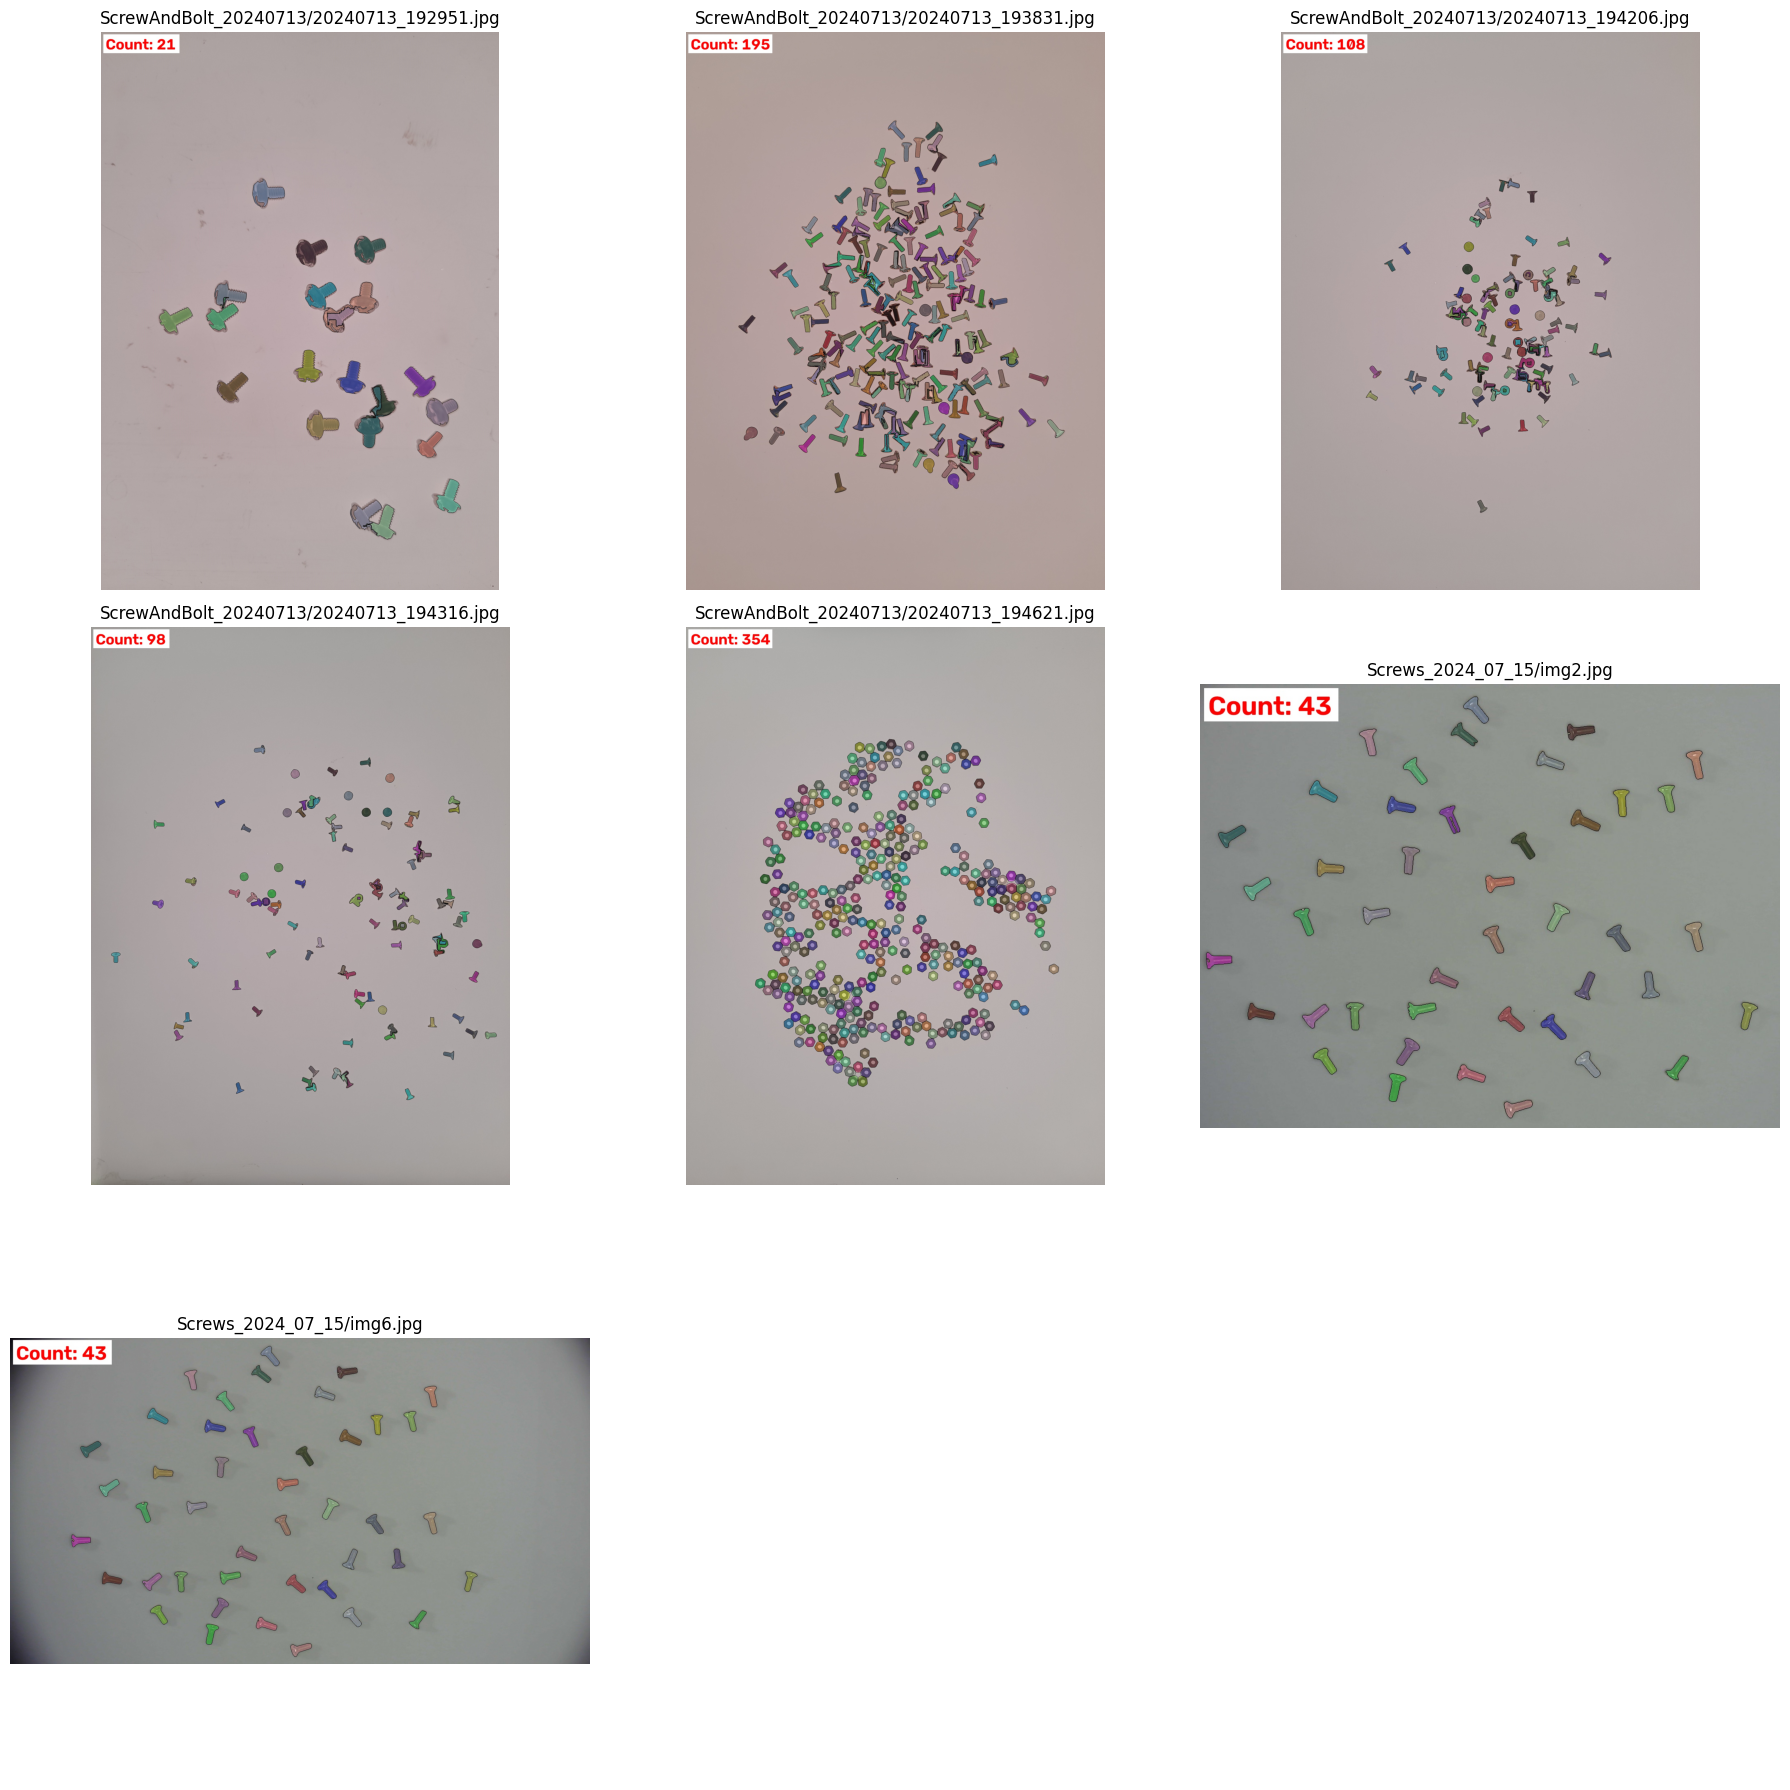

In [8]:
show = IMAGES[::4]
cols = 3
fig, axes = plt.subplots(int(np.ceil(len(show) / cols)), cols, figsize=(18, 6 * int(np.ceil(len(show) / cols))))
for ax in axes.ravel():
    ax.axis("off")
for ax, path in zip(axes.ravel(), show):
    name = os.path.relpath(path, DATA_DIR).replace(os.sep, "/")
    ax.imshow(cv2.cvtColor(cv2.imread(os.path.join(OUT_DIR, name.replace("/", "__"))), cv2.COLOR_BGR2RGB))
    ax.set_title(name)
plt.tight_layout()
plt.show()